[*********************100%***********************]  3 of 3 completed


Ticker
AAPL    0.001276
GOOG    0.000311
MSFT    0.000354
dtype: float64
Expected Annual Return: 23.61%
Annual Volatility: 24.48%
Sharpe Ratio: 0.80


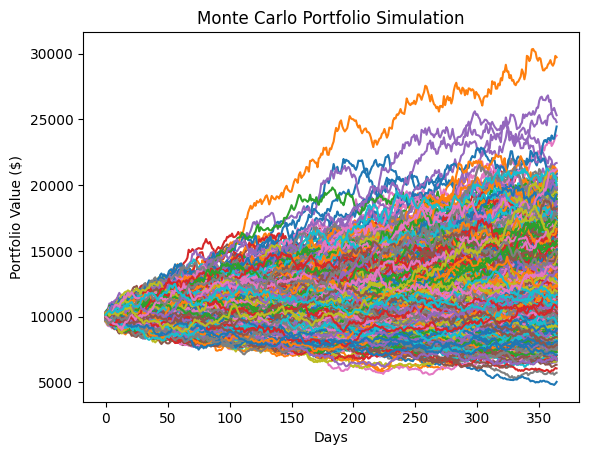

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
import yfinance as yf
#import data
def get_data(stocks, start, end):
    stock_data = yf.download(stocks, start=start, end=end, auto_adjust=False)
    stock_data = stock_data['Close']

    returns = stock_data.pct_change().dropna()

    mean_returns = returns.mean()
    cov_matrix = returns.cov()
    return mean_returns, cov_matrix

stock_list = ["AAPL", "MSFT", "GOOG"]
stocks = [stock for stock in stock_list]
end_date = dt.datetime.now()
start_date = end_date - dt.timedelta(days=365)

mean_returns, cov_matrix = get_data(stocks, start_date, end_date)

print(mean_returns)

# Portfolio weights
weights = np.array([1/3, 1/3, 1/3])
# Monte Carlo settings
num_simulations = 1000
num_days = 365
initial_portfolio = 10000

# Annualized expected portfolio return
annual_return = np.dot(weights, mean_returns) * 365

# Annualized portfolio volatility
annual_volatility = np.sqrt(
    weights.T @ cov_matrix @ weights
) * np.sqrt(365)

# Risk-free rate
risk_free_rate = 0.04

# Sharpe Ratio
sharpe_ratio = (
    annual_return - risk_free_rate
) / annual_volatility

print(f"Expected Annual Return: {annual_return * 100:.2f}%")
print(f"Annual Volatility: {annual_volatility * 100:.2f}%")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")

# Store simulation results

simulation_results = np.zeros((num_days, num_simulations))

np.random.seed(42)

for simulation in range(num_simulations):

    # Generate random returns for each stock
    random_returns = np.random.multivariate_normal(
        mean_returns,
        cov_matrix,
        num_days
    )

    # Calculate portfolio return each day
    portfolio_returns = random_returns @ weights

    # Calculate portfolio value over time
    portfolio_values = initial_portfolio * np.cumprod(1 + portfolio_returns)

    simulation_results[:, simulation] = portfolio_values


# Plot simulations
plt.plot(simulation_results)
plt.xlabel("Days")
plt.ylabel("Portfolio Value ($)")
plt.title("Monte Carlo Portfolio Simulation")
plt.show()

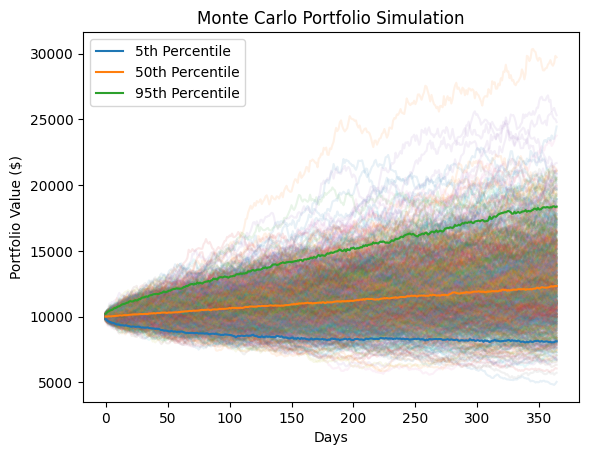

In [15]:
# Calculate percentile lines
percentile_5 = np.percentile(simulation_results, 5, axis=1)
percentile_50 = np.percentile(simulation_results, 50, axis=1)
percentile_95 = np.percentile(simulation_results, 95, axis=1)

# Plot
plt.plot(simulation_results, alpha=0.1)

plt.plot(percentile_5, label="5th Percentile")
plt.plot(percentile_50, label="50th Percentile")
plt.plot(percentile_95, label="95th Percentile")

plt.xlabel("Days")
plt.ylabel("Portfolio Value ($)")
plt.title("Monte Carlo Portfolio Simulation")
plt.legend()
plt.savefig("simulation_paths.png", dpi=200, bbox_inches="tight")
plt.show()

In [16]:
# Get final portfolio value from every simulation
final_values = simulation_results[-1, :]
# -----------------------------
# VaR AND CVaR
# -----------------------------

percentile_5_final = np.percentile(final_values, 5)

var_95 = initial_portfolio - percentile_5_final

worst_cases = final_values[
    final_values <= percentile_5_final
]

cvar_95 = (
    initial_portfolio
    - np.mean(worst_cases)
)

probability_of_loss = np.mean(
    final_values < initial_portfolio
)

print("\n--- Monte Carlo Results ---")

print(
    f"Initial Portfolio: "
    f"${initial_portfolio:,.2f}"
)

print(
    f"Average Ending Value: "
    f"${np.mean(final_values):,.2f}"
)

print(
    f"Median Ending Value: "
    f"${np.median(final_values):,.2f}"
)

print(
    f"5th Percentile: "
    f"${np.percentile(final_values, 5):,.2f}"
)

print(
    f"95th Percentile: "
    f"${np.percentile(final_values, 95):,.2f}"
)

print(
    f"Probability of Loss: "
    f"{probability_of_loss * 100:.2f}%"
)

print(
    f"95% Value at Risk: "
    f"${var_95:,.2f}"
)

print(
    f"95% Expected Shortfall: "
    f"${cvar_95:,.2f}"
)
print("\n--- Portfolio Characteristics ---")

print(f"Expected Annual Return: {annual_return * 100:.2f}%")
print(f"Annual Volatility: {annual_volatility * 100:.2f}%")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")


--- Monte Carlo Results ---
Initial Portfolio: $10,000.00
Average Ending Value: $12,680.97
Median Ending Value: $12,316.29
5th Percentile: $8,113.00
95th Percentile: $18,361.92
Probability of Loss: 20.50%
95% Value at Risk: $1,887.00
95% Expected Shortfall: $2,609.32

--- Portfolio Characteristics ---
Expected Annual Return: 23.61%
Annual Volatility: 24.48%
Sharpe Ratio: 0.80


In [17]:
# -----------------------------
# MAX DRAWDOWN
# -----------------------------

# Add the initial $10,000 value to the beginning of every simulation
simulation_with_initial = np.vstack([
    np.full((1, num_simulations), initial_portfolio),
    simulation_results
])

# Highest portfolio value reached up to each point
running_max = np.maximum.accumulate(
    simulation_with_initial,
    axis=0
)

# Percentage decline from previous peak
drawdowns = (
    simulation_with_initial - running_max
) / running_max

# Worst drawdown experienced in each simulation
max_drawdowns = drawdowns.min(axis=0)

# Convert negative drawdowns into positive magnitudes
max_drawdown_magnitudes = -max_drawdowns
# Summary statistics
average_max_drawdown = np.mean(max_drawdown_magnitudes)
median_max_drawdown = np.median(max_drawdown_magnitudes)
drawdown_95 = np.percentile(max_drawdown_magnitudes, 95)

In [18]:
print("\n--- Risk Measures ---")

print(f"95% VaR: ${var_95:,.2f}")

print(
    f"95% CVaR / Expected Shortfall: "
    f"${cvar_95:,.2f}"
)

print(
    f"Average Maximum Drawdown: "
    f"{average_max_drawdown * 100:.2f}%"
)

print(
    f"Median Maximum Drawdown: "
    f"{median_max_drawdown * 100:.2f}%"
)

print(
    f"95th Percentile Maximum Drawdown: "
    f"{drawdown_95 * 100:.2f}%"
)


--- Risk Measures ---
95% VaR: $1,887.00
95% CVaR / Expected Shortfall: $2,609.32
Average Maximum Drawdown: 19.53%
Median Maximum Drawdown: 17.95%
95th Percentile Maximum Drawdown: 33.73%


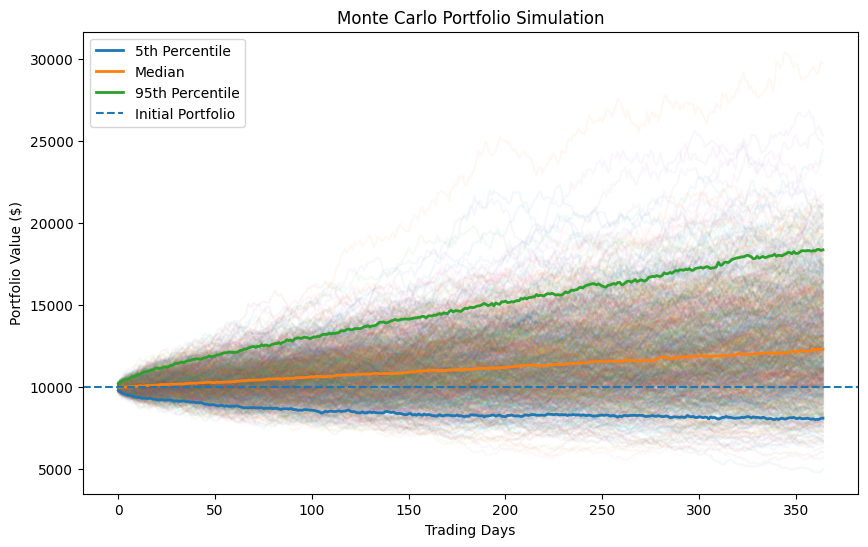

In [19]:
#montecarlo graph
plt.figure(figsize=(10, 6))

# All simulations
plt.plot(
    simulation_results,
    alpha=0.05
)

# Percentile paths
plt.plot(
    percentile_5,
    linewidth=2,
    label="5th Percentile"
)

plt.plot(
    percentile_50,
    linewidth=2,
    label="Median"
)

plt.plot(
    percentile_95,
    linewidth=2,
    label="95th Percentile"
)

plt.axhline(
    initial_portfolio,
    linestyle="--",
    label="Initial Portfolio"
)

plt.xlabel("Trading Days")
plt.ylabel("Portfolio Value ($)")
plt.title("Monte Carlo Portfolio Simulation")

plt.legend()

plt.show()

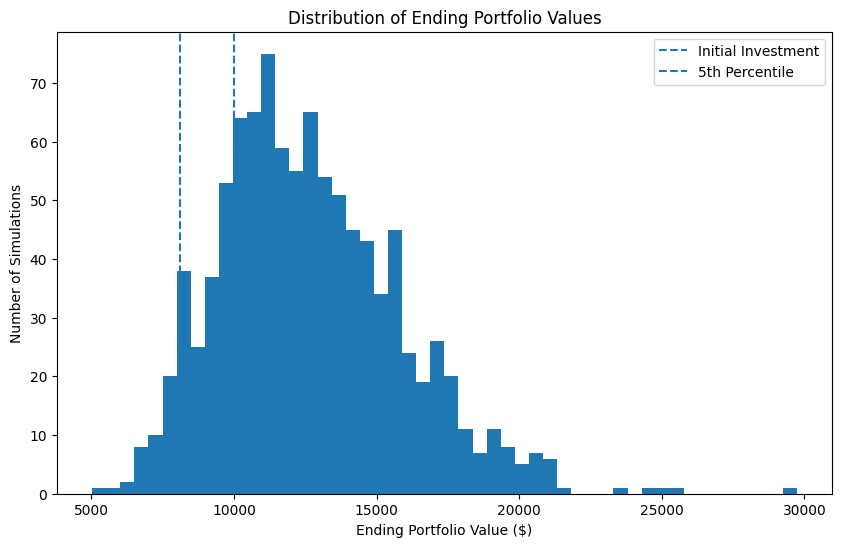

In [20]:
#ENDING VALUE DISTRIBUTION
plt.figure(figsize=(10, 6))

plt.hist(
    final_values,
    bins=50
)

plt.axvline(
    initial_portfolio,
    linestyle="--",
    label="Initial Investment"
)

plt.axvline(
    percentile_5_final,
    linestyle="--",
    label="5th Percentile"
)

plt.xlabel("Ending Portfolio Value ($)")
plt.ylabel("Number of Simulations")
plt.title("Distribution of Ending Portfolio Values")

plt.legend()
plt.savefig("ending_value_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
#rebalancing, transaction costs/ small management fee, rolling means/covariances, bootstrap simulation, stress scenarios
#BACKTESTTTTTTTTTTTT your model: pretend you were standing one year ago, simulate forward, then compare the simulated range with what actually happened
